# Summit County Home Values, 2019 to 2025
Jonathan Satina, EMAT 32210 Final Project: Data in Hand

My question is whether the cheaper zip codes in Summit County saw bigger percentage increases in home value from 2019 to 2025 than the more expensive ones like Hudson. If they did, the price gap across the county is shrinking.

## Data Collection
The data comes from Zillow Research's public housing data page (zillow.com/research/data). I used the Zillow home value index for All Homes (single family and condo). ZHVI is Zillow's estimate of the typical home value in an area, and this version reflects homes in the 35th to 65th percentile range. The full file covers every ZIP code Zillow tracks in the US (27,996 rows, about 125 MB), so I filtered it down to the rows where the state is Ohio and the county is Summit County and saved that as data/summit_county_zhvi.csv. My copy was downloaded on November 22, 2026 and runs through October 2026. The cell below reproduces that step.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

ZILLOW_URL = "https://files.zillowstatic.com/research/public_csvs/zhvi/Zip_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
PATH = "data/summit_county_zhvi.csv"

if not os.path.exists(PATH):
    full = pd.read_csv(ZILLOW_URL, dtype={"RegionName": str})
    summit = full[(full["State"] == "OH") & (full["CountyName"] == "Summit County")]
    os.makedirs("data", exist_ok=True)
    summit.to_csv(PATH, index=False)

df = pd.read_csv(PATH, dtype={"RegionName": str})
df.shape

(31, 329)

In [2]:
df.iloc[:, :12].head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,City,Metro,CountyName,2000-03-31,2000-04-30,2000-05-31
0,77065,2098,44203,zip,OH,OH,Barberton,"Akron, OH",Summit County,87059.692226,87586.943143,88176.825445
1,77076,2360,44224,zip,OH,OH,Stow,"Akron, OH",Summit County,136431.535198,136740.890081,136971.036552
2,77126,3362,44312,zip,OH,OH,Lakemore,"Akron, OH",Summit County,89208.484379,89168.163208,89242.140232
3,77073,3953,44221,zip,OH,OH,Cuyahoga Falls,"Akron, OH",Summit County,88014.838633,88244.106021,88475.402065
4,77291,4521,44685,zip,OH,OH,Uniontown,"Akron, OH",Summit County,140697.724690,140934.659816,141502.056263


In [3]:
id_cols = list(df.columns[:9])
date_cols = list(df.columns[9:])
print("ID columns:", id_cols)
print("Number of monthly columns:", len(date_cols))
print("First month:", date_cols[0], " Last month:", date_cols[-1])

ID columns: ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'City', 'Metro', 'CountyName']
Number of monthly columns: 320
First month: 2000-03-31  Last month: 2026-10-31


In [4]:
df[id_cols].dtypes

RegionID      int64
SizeRank      int64
RegionName      str
RegionType      str
StateName       str
State           str
City            str
Metro           str
CountyName      str
dtype: object

In [5]:
df[date_cols].dtypes.value_counts()

float64    320
Name: count, dtype: int64

In [6]:
df[["RegionName", "City"]].sort_values(["City", "RegionName"]).reset_index(drop=True)

,RegionName,City
0,44301,Akron
1,44302,Akron
2,44303,Akron
3,44304,Akron
4,44305,Akron
5,44306,Akron
6,44307,Akron
7,44310,Akron
8,44311,Akron
9,44313,Akron


In [7]:
df["City"].value_counts()

City
Akron             13
Lakemore           2
Cuyahoga Falls     2
Barberton          1
Stow               1
Uniontown          1
Twinsburg          1
Hudson             1
Northfield         1
Fairlawn           1
Tallmadge          1
Copley             1
Macedonia          1
Clinton            1
Richfield          1
Munroe Falls       1
Peninsula          1
Name: count, dtype: int64

In [8]:
missing = df[date_cols].isna().sum()
missing[missing > 0]

2004-03-31    1
dtype: int64

In [9]:
df.loc[df["2004-03-31"].isna(), ["RegionName", "City", "2004-02-29", "2004-03-31", "2004-04-30"]]

,RegionName,City,2004-02-29,2004-03-31,2004-04-30
20,44056,Macedonia,185545.09718,NaN,188221.767826


In [10]:
df[id_cols].nunique()

RegionID      31
SizeRank      31
RegionName    31
RegionType     1
StateName      1
State          1
City          17
Metro          1
CountyName     1
dtype: int64

In [11]:
drop_cols = ["RegionID", "RegionType", "StateName", "State", "Metro", "CountyName"]
clean = df.drop(columns=drop_cols)
print(clean.shape)
clean.iloc[:, :6].head()

(31, 323)


,SizeRank,RegionName,City,2000-03-31,2000-04-30,2000-05-31
0,2098,44203,Barberton,87059.692226,87586.943143,88176.825445
1,2360,44224,Stow,136431.535198,136740.890081,136971.036552
2,3362,44312,Lakemore,89208.484379,89168.163208,89242.140232
3,3953,44221,Cuyahoga Falls,88014.838633,88244.106021,88475.402065
4,4521,44685,Uniontown,140697.724690,140934.659816,141502.056263


In [12]:
long = clean.melt(id_vars=["RegionName", "City"], value_vars=date_cols, var_name="Date", value_name="ZHVI")
long["Date"] = pd.to_datetime(long["Date"])
print(long.shape)
long.head()

(9920, 4)


,RegionName,City,Date,ZHVI
0,44203,Barberton,2000-03-31,87059.692226
1,44224,Stow,2000-03-31,136431.535198
2,44312,Lakemore,2000-03-31,89208.484379
3,44221,Cuyahoga Falls,2000-03-31,88014.838633
4,44685,Uniontown,2000-03-31,140697.724690


In [13]:
long["ZHVI"].describe().round(2)

count      9919.00
mean     149856.45
std       89115.53
min       26757.89
25%       76894.83
50%      134007.28
75%      201063.53
max      543549.27
Name: ZHVI, dtype: float64

In [14]:
summary = clean[["RegionName", "City", "2019-12-31", "2025-12-31"]].copy()
summary.columns = ["Zip", "City", "Dec2019", "Dec2025"]
summary["PctChange"] = (summary["Dec2025"] / summary["Dec2019"] - 1) * 100
summary = summary.sort_values("Dec2019").reset_index(drop=True)
summary.round(1)

,Zip,City,Dec2019,Dec2025,PctChange
0,44311,Akron,42974.3,73831.2,71.8
1,44307,Akron,48174.0,81056.8,68.3
2,44306,Akron,52789.5,90827.9,72.1
3,44304,Akron,59241.9,92639.2,56.4
4,44314,Akron,61444.4,107191.1,74.5
5,44310,Akron,69841.1,116368.3,66.6
6,44301,Akron,69854.7,120441.8,72.4
7,44250,Lakemore,72024.9,110084.2,52.8
8,44320,Akron,73427.0,116055.2,58.1
9,44305,Akron,73676.6,122789.3,66.7


In [15]:
summary[["Dec2019", "Dec2025", "PctChange"]].describe().round(1)

,Dec2019,Dec2025,PctChange
count,31.0,31.0,31.0
mean,155447.4,234534.4,55.2
std,87788.0,123501.3,9.6
min,42974.3,73831.2,41.5
25%,72726.0,118405.1,48.6
50%,159318.8,245159.7,51.6
75%,202991.0,302750.4,62.3
max,351431.3,524245.9,74.5


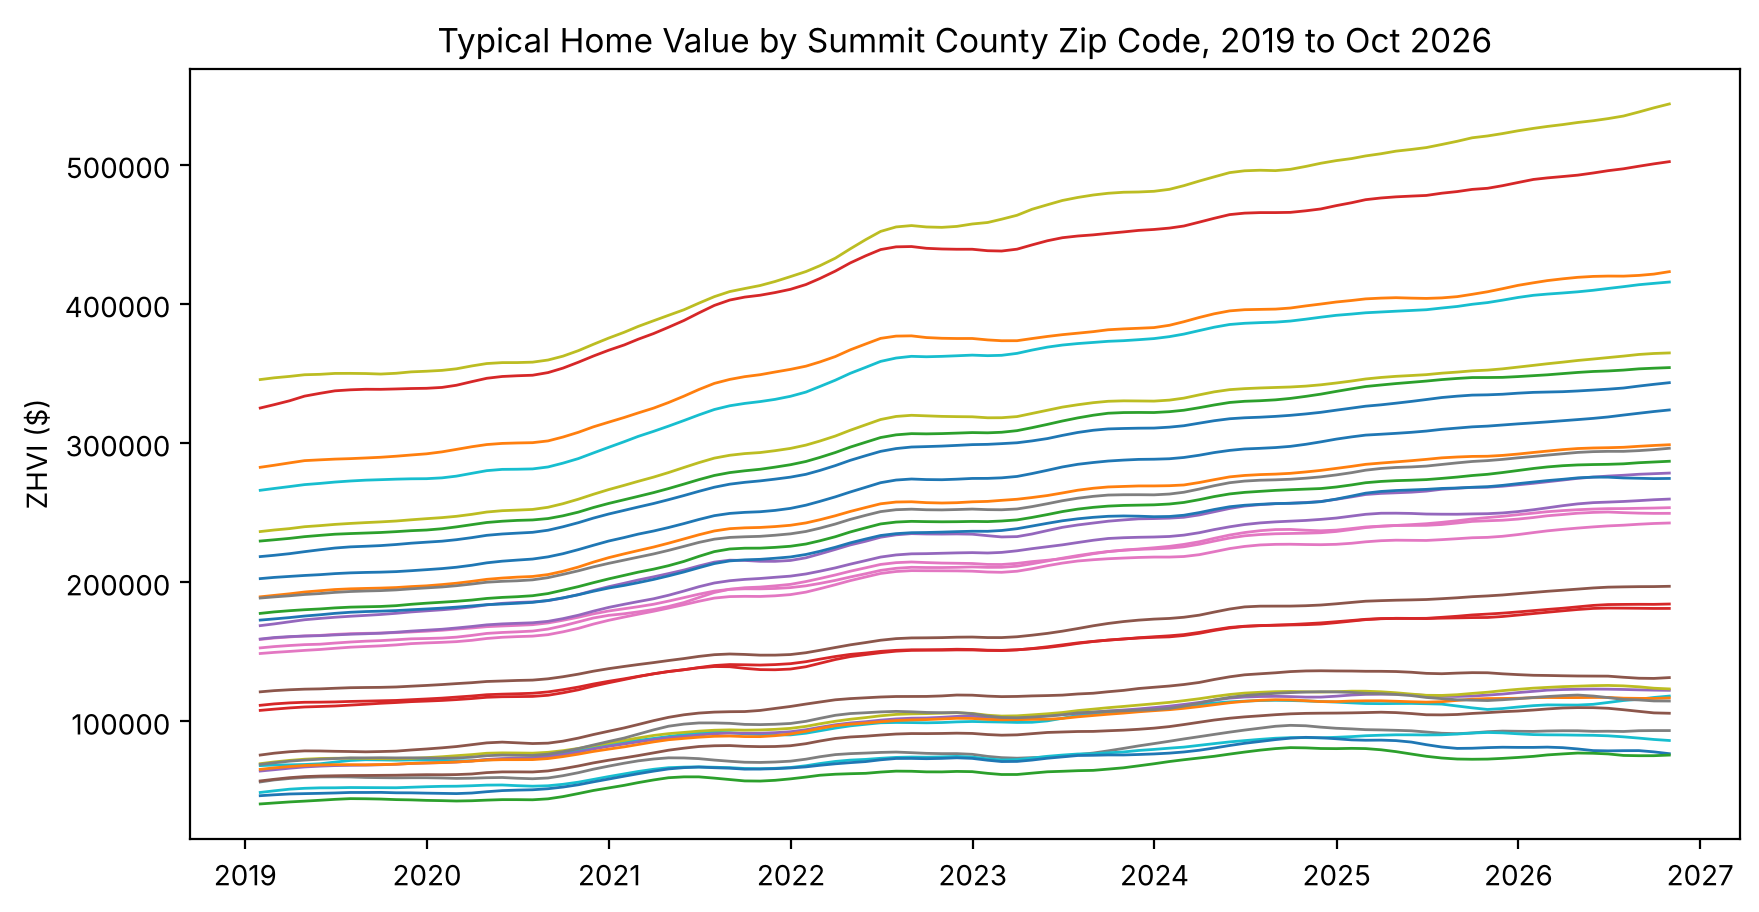

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
for zip_code, g in long[long["Date"] >= "2019-01-01"].groupby("RegionName"):
    ax.plot(g["Date"], g["ZHVI"], linewidth=1)
ax.set_title("Typical Home Value by Summit County Zip Code, 2019 to Oct 2026")
ax.set_ylabel("ZHVI ($)")
plt.show()

## Data Description
The raw data is a single CSV with 31 rows and 329 columns. Each row is one ZIP code in Summit County. The first nine columns describe the ZIP code: RegionID (Zillow's internal ID), SizeRank (Zillow's ranking by size, where a smaller number means a bigger market), RegionName (the five digit ZIP code, which I read in as text so it's treated as a label and not a number), RegionType (always "zip"), StateName and State (always OH), City, Metro (always "Akron, OH") and CountyName (always Summit County). RegionID and SizeRank are integers and the rest of the ID columns are text. The other 320 columns are one per month from March 2000 to October 2026, each named by the last day of the month, and each holds that ZIP code's typical home value in dollars as a float.

For cleanup I dropped RegionType, StateName, State, Metro and CountyName because they have the same value in every row, and RegionID because it is just an internal Zillow ID for the zip code, which leaves 31 rows and 323 columns. The data is in wide format, so I also melted it into long format with one row per ZIP code per month (9,920 rows), which will be easier for plotting and grouping later. A few things to keep in mind are that City is Zillow's name for the ZIP code's main city, so 13 different ZIP codes are labeled Akron and two each are labeled Lakemore and Cuyahoga Falls, and that not every Summit County ZIP code is in Zillow's data. Bath, which I mentioned in my proposal, doesn't show up as its own ZIP code, so Hudson (44236) and Richfield (44286) will stand in as the high end of the county. For my question I'll compare each ZIP code's December 2019 value to its December 2025 value. In December 2019 the typical value ranged from about $43,000 in 44311 (Akron) to about $351,000 in Hudson.